# Building a Financial Transaction Network — A Foundational Network Science Project

*An end-to-end template: from conceptual design → synthetic data → graph construction → topology analytics → interactive visualization.*

This notebook walks through the **full modeling lifecycle** for a network science project,
using a **financial money-flow network** as a concrete, practical example. It is written to be
modular and reusable: swap out the data-generation layer for a real ledger and the rest of the
pipeline still applies.

**Stack:** `networkx` (graph engine) · `pandas`/`numpy` (data) · `pyvis` (interactive viz) · `matplotlib` (distributions).


## 1. Conceptual Framework & Problem Design

Before writing a single line of graph code, a network science project must answer four
foundational modeling questions. Getting these right *up front* determines whether the
resulting graph can actually answer the questions you care about.

> **Business motivation:** We want to map how money moves between bank accounts so we can
> surface **hub accounts** (heavily-used intermediaries) and **suspicious flow paths**
> (chains that funnel value toward a small set of destinations) — the bread-and-butter of
> anti-money-laundering (AML) and fraud analytics.

### ❶ What is the network being built?
A **money-flow network**: a model of aggregated financial value moving between bank accounts
over a time window. We choose the following graph type, and the choice is deliberate:

| Property | Choice | Why |
|---|---|---|
| **Directed** | `DiGraph` | Money flows *from* a sender *to* a receiver — direction is the whole point. |
| **Weighted** | yes | Not all flows are equal; a \$1M transfer ≠ a \$5 transfer. |
| **Temporal** | yes (edge attribute) | We retain the last activity timestamp so the static graph can later be sliced into time windows. |

### ❷ What are the nodes?
**Bank accounts.** Each node is one account, carrying descriptive attributes:

| Attribute | Meaning |
|---|---|
| `account_id` | Unique identifier (the node key) |
| `acct_type` | `personal` · `business` · `merchant` |
| `region` | Geographic region of the account holder |
| `open_date` | When the account was opened |
| `risk_flag` | Whether the account is already on a watch-list |

### ❸ How will the edges be defined?
A **directed edge `A → B`** exists if account `A` sent money to account `B` during the window.
Because two accounts may transact many times, we **aggregate** the raw ledger into one edge per
ordered pair, carrying:

| Edge attribute | Definition |
|---|---|
| `weight` | **Total amount** sent `A → B` (the primary edge strength) |
| `txn_count` | Number of individual transactions `A → B` |
| `avg_amount` | Mean transaction size |
| `last_ts` | Timestamp of the most recent transaction (temporal anchor) |

### ❹ What data do we need to support the edge definition?
Two tables — exactly what a bank's data warehouse would expose:

1. **Account registry** → the *node* table (`accounts_df`): one row per account with its attributes.
2. **Transaction ledger** → the raw *event* table (`transactions_df`): one row per transaction
   `(sender, receiver, amount, timestamp)`.

The edge table (`edges_df`) is **derived** by aggregating the ledger. This separation —
*raw events* vs. *aggregated edges* — is the key data-engineering pattern that makes the edge
definition reproducible and tunable (e.g. re-aggregate over a different window).


## 2. Synthetic Data Generation & Loading

We generate a clean, reproducible mock dataset that *perfectly supports* the edge definition
above. The generators are modular — replace their bodies with real DB queries and the rest of
the notebook is unchanged.

We deliberately seed a handful of **hub accounts** that receive a disproportionate share of
flows, so that the centrality analytics later have something interesting to find.


In [1]:
# --- Imports & global configuration -----------------------------------------
from datetime import datetime, timedelta

import numpy as np
import pandas as pd
import networkx as nx

# Reproducibility: a single master seed drives every random draw.
SEED = 42
N_ACCOUNTS = 60       # number of accounts (nodes)
N_TXNS = 1200         # number of raw transactions (events)
N_HUBS = 4            # accounts deliberately made into flow hubs

ACCT_TYPES = ["personal", "business", "merchant"]
REGIONS = ["North", "South", "East", "West", "Central"]

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
print("Config loaded — building a", "DIRECTED, WEIGHTED, TEMPORAL", "financial network.")

Config loaded — building a DIRECTED, WEIGHTED, TEMPORAL financial network.


In [2]:
def generate_accounts(n: int = N_ACCOUNTS, seed: int = SEED) -> pd.DataFrame:
    """Build the NODE table: one row per bank account with descriptive attributes.

    Returns a tidy DataFrame keyed by ``account_id`` — this becomes the node set
    and its columns become node attributes on the graph.
    """
    rng = np.random.default_rng(seed)
    account_ids = [f"ACC{idx:04d}" for idx in range(1, n + 1)]
    base_open = datetime(2018, 1, 1)

    accounts = pd.DataFrame({
        "account_id": account_ids,
        # Most accounts are personal; businesses and merchants are rarer.
        "acct_type": rng.choice(ACCT_TYPES, size=n, p=[0.6, 0.25, 0.15]),
        "region": rng.choice(REGIONS, size=n),
        # Opened on a random day within ~6 years.
        "open_date": [base_open + timedelta(days=int(d))
                      for d in rng.integers(0, 6 * 365, size=n)],
        # ~12% of accounts already sit on a watch-list.
        "risk_flag": rng.random(n) < 0.12,
    })
    return accounts


accounts_df = generate_accounts()
print(f"Generated {len(accounts_df)} accounts (nodes).")
accounts_df.head()

Generated 60 accounts (nodes).


,account_id,acct_type,region,open_date,risk_flag
0,ACC0001,business,East,2023-08-17,False
1,ACC0002,personal,West,2018-11-30,False
2,ACC0003,merchant,West,2020-12-25,True
3,ACC0004,business,East,2022-03-05,False
4,ACC0005,personal,Central,2020-12-21,True


In [3]:
def generate_transactions(accounts_df: pd.DataFrame,
                          n_txns: int = N_TXNS,
                          n_hubs: int = N_HUBS,
                          seed: int = SEED) -> tuple[pd.DataFrame, list[str]]:
    """Build the raw EVENT table: one row per individual transaction.

    A few ``hub`` accounts are chosen to receive (and occasionally send) an
    outsized share of flows, so the network has realistic high-centrality nodes.

    Returns ``(transactions_df, hubs)``.
    """
    rng = np.random.default_rng(seed + 1)
    ids = accounts_df["account_id"].to_numpy()
    hubs = list(rng.choice(ids, size=n_hubs, replace=False))
    base_ts = datetime(2024, 1, 1)

    rows = []
    for _ in range(n_txns):
        roll = rng.random()
        if roll < 0.35:                      # money flowing INTO a hub
            sender, receiver = rng.choice(ids), rng.choice(hubs)
        elif roll < 0.45:                    # money flowing OUT of a hub
            sender, receiver = rng.choice(hubs), rng.choice(ids)
        else:                                # ordinary peer-to-peer flow
            sender, receiver = rng.choice(ids, size=2, replace=False)
        if sender == receiver:
            continue                         # no self-loops

        rows.append({
            "sender": sender,
            "receiver": receiver,
            # Lognormal => realistic skew: many small, few very large transfers.
            "amount": round(float(rng.lognormal(mean=6.0, sigma=1.1)), 2),
            "timestamp": base_ts + timedelta(days=int(rng.integers(0, 180)),
                                             seconds=int(rng.integers(0, 86400))),
        })

    transactions_df = pd.DataFrame(rows)
    return transactions_df, hubs


transactions_df, HUBS = generate_transactions(accounts_df)
print(f"Generated {len(transactions_df)} raw transactions (events).")
print(f"Seeded hub accounts: {HUBS}")
transactions_df.head()

Generated 1196 raw transactions (events).
Seeded hub accounts: ['ACC0038', 'ACC0003', 'ACC0029', 'ACC0024']


,sender,receiver,amount,timestamp
0,ACC0058,ACC0050,410.89,2024-03-09 06:19:43
1,ACC0029,ACC0028,1138.56,2024-03-11 21:24:20
2,ACC0047,ACC0003,167.59,2024-03-23 00:05:52
3,ACC0033,ACC0024,271.67,2024-03-12 12:50:35
4,ACC0049,ACC0057,603.55,2024-04-16 22:23:12


In [4]:
def build_edges(transactions_df: pd.DataFrame) -> pd.DataFrame:
    """Aggregate the raw ledger into the EDGE table — one row per directed pair.

    This is the step that realises our edge definition: a directed edge A -> B
    summarising every transaction from A to B.
    """
    edges = (
        transactions_df
        .groupby(["sender", "receiver"], as_index=False)
        .agg(
            weight=("amount", "sum"),        # total value flowed A -> B (edge strength)
            txn_count=("amount", "size"),    # number of transactions
            avg_amount=("amount", "mean"),   # mean transaction size
            last_ts=("timestamp", "max"),    # temporal anchor: most recent activity
        )
    )
    edges["weight"] = edges["weight"].round(2)
    edges["avg_amount"] = edges["avg_amount"].round(2)
    return edges


edges_df = build_edges(transactions_df)
print(f"Aggregated into {len(edges_df)} directed edges "
      f"(from {len(transactions_df)} raw transactions).")
edges_df.sort_values("weight", ascending=False).head()

Aggregated into 853 directed edges (from 1196 raw transactions).


,sender,receiver,weight,txn_count,avg_amount,last_ts
488,ACC0033,ACC0045,14432.75,1,14432.75,2024-04-16 04:29:08
58,ACC0003,ACC0042,13070.83,2,6535.42,2024-06-01 05:39:16
572,ACC0039,ACC0025,12809.74,1,12809.74,2024-03-24 02:53:52
108,ACC0006,ACC0051,9794.94,1,9794.94,2024-06-26 18:03:24
469,ACC0032,ACC0024,9518.96,3,3172.99,2024-05-11 04:33:09


## 3. Network Construction

We now load the two dataframes into a `networkx.DiGraph`:

1. **Edges** come from `edges_df` via `from_pandas_edgelist`, carrying every edge attribute.
2. **Node attributes** come from `accounts_df` via `set_node_attributes`.

A `1/weight` **`distance`** attribute is also attached to each edge so that shortest-path-based
metrics (betweenness) treat *high-value* flows as *short* hops.


In [5]:
def build_graph(edges_df: pd.DataFrame, accounts_df: pd.DataFrame) -> nx.DiGraph:
    """Assemble the directed, weighted graph from the edge and node tables."""
    # 1. Edges + their attributes (this also creates the node set).
    G = nx.from_pandas_edgelist(
        edges_df,
        source="sender",
        target="receiver",
        edge_attr=["weight", "txn_count", "avg_amount", "last_ts"],
        create_using=nx.DiGraph,
    )

    # 2. Attach node attributes from the account registry.
    #    Only accounts that actually transacted appear as nodes.
    node_attrs = accounts_df.set_index("account_id").to_dict(orient="index")
    nx.set_node_attributes(G, node_attrs)

    # 3. Derived edge attribute: distance = 1 / weight (for weighted shortest paths).
    for _, _, data in G.edges(data=True):
        data["distance"] = 1.0 / data["weight"] if data["weight"] > 0 else np.inf

    return G


G = build_graph(edges_df, accounts_df)

print(f"Directed?      {G.is_directed()}")
print(f"# nodes:       {G.number_of_nodes()}")
print(f"# edges:       {G.number_of_edges()}")
# Example: peek at one node and one edge to confirm attributes mapped correctly.
sample_node = next(iter(G.nodes))
print(f"\nSample node  {sample_node}: {G.nodes[sample_node]}")
u, v, d = next(iter(G.edges(data=True)))
print(f"Sample edge  {u} -> {v}: {d}")

Directed?      True
# nodes:       60
# edges:       853

Sample node  ACC0001: {'acct_type': 'business', 'region': 'East', 'open_date': Timestamp('2023-08-17 00:00:00'), 'risk_flag': False}
Sample edge  ACC0001 -> ACC0003: {'weight': 1486.47, 'txn_count': 3, 'avg_amount': 495.49, 'last_ts': Timestamp('2024-06-21 22:49:05'), 'distance': 0.0006727347339670495}


## 4. Network Topology & Analytics

With the graph built, we quantify its structure. These metrics are the standard first pass on
*any* network: how connected is it, how is influence distributed, and who are the key players?


In [6]:
# --- Density & sparsity ------------------------------------------------------
# Density = actual edges / possible edges. Real-world networks are almost always
# extremely sparse (density << 1), which is exactly why graph methods scale.
density = nx.density(G)
sparsity = 1.0 - density

print(f"Density:   {density:.4f}  (fraction of all possible directed edges present)")
print(f"Sparsity:  {sparsity:.4f}  (1 - density)")
print(f"Possible directed edges: {G.number_of_nodes() * (G.number_of_nodes() - 1):,}")
print(f"Actual edges:            {G.number_of_edges():,}")

Density:   0.2410  (fraction of all possible directed edges present)
Sparsity:  0.7590  (1 - density)
Possible directed edges: 3,540
Actual edges:            853


Degree summary statistics:
       in_degree  out_degree  total_degree
count      60.00       60.00         60.00
mean       14.22       14.22         28.43
std        10.21        5.10         14.52
min         7.00        7.00         18.00
25%        10.00       11.00         23.00
50%        12.00       13.00         25.00
75%        14.00       16.00         27.00
max        54.00       32.00         83.00


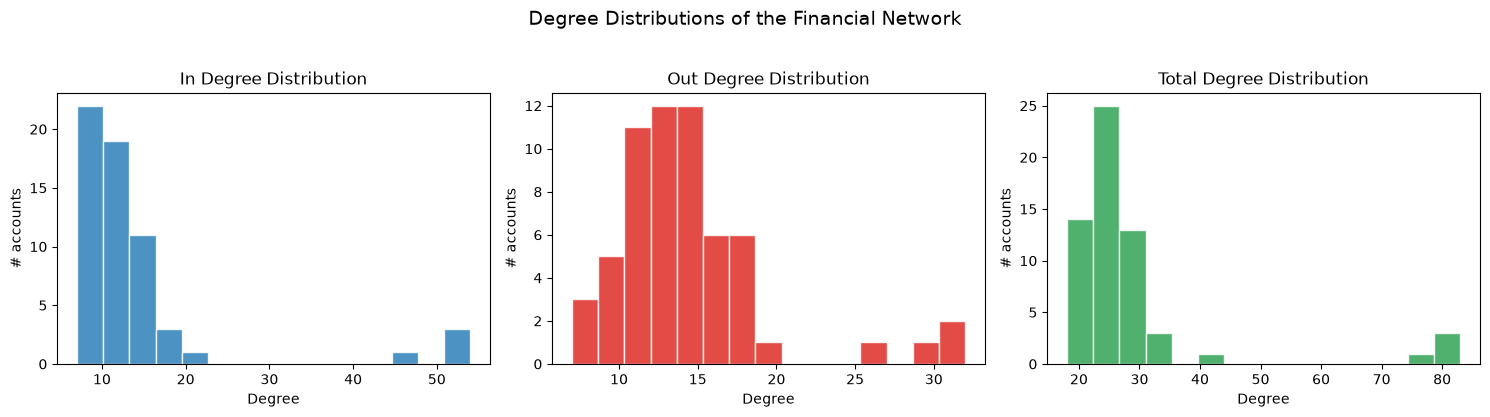

In [7]:
# --- Degree distribution -----------------------------------------------------
# For a directed graph, in-degree (incoming flows) and out-degree (outgoing) tell
# different stories. Hubs typically show up as high IN-degree (money sinks).
import matplotlib.pyplot as plt

deg_df = pd.DataFrame({
    "in_degree": dict(G.in_degree()),
    "out_degree": dict(G.out_degree()),
})
deg_df["total_degree"] = deg_df["in_degree"] + deg_df["out_degree"]

print("Degree summary statistics:")
print(deg_df.describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, color in zip(axes,
                          ["in_degree", "out_degree", "total_degree"],
                          ["#2c7fb8", "#de2d26", "#31a354"]):
    ax.hist(deg_df[col], bins=15, color=color, edgecolor="white", alpha=0.85)
    ax.set_title(f"{col.replace('_', ' ').title()} Distribution")
    ax.set_xlabel("Degree")
    ax.set_ylabel("# accounts")
fig.suptitle("Degree Distributions of the Financial Network", fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

In [8]:
# --- Clustering coefficient --------------------------------------------------
# Clustering is defined on UNDIRECTED graphs, so we measure it on the undirected
# projection: "when A and B both transact with C, do A and B also transact?"
G_und = G.to_undirected()
avg_clustering = nx.average_clustering(G_und)
transitivity = nx.transitivity(G_und)

print(f"Average clustering coefficient (undirected projection): {avg_clustering:.4f}")
print(f"Global transitivity:                                    {transitivity:.4f}")

Average clustering coefficient (undirected projection): 0.5163
Global transitivity:                                    0.4742


In [9]:
# --- Centrality measures -----------------------------------------------------
# Each centrality answers a different notion of "importance":
#   * in/out-degree   -> raw volume of distinct counterparties
#   * betweenness     -> how often an account lies on high-value flow paths (broker role)
#   * eigenvector     -> being connected to other well-connected accounts (influence)
in_dc = nx.in_degree_centrality(G)
out_dc = nx.out_degree_centrality(G)

# Betweenness uses the 1/weight distance so big-money flows count as short hops.
betweenness = nx.betweenness_centrality(G, weight="distance", normalized=True)

# Eigenvector via the numpy solver -> robust on directed, weighted graphs.
try:
    eigenvector = nx.eigenvector_centrality_numpy(G, weight="weight")
except Exception:  # pragma: no cover - fallback for degenerate graphs
    eigenvector = nx.eigenvector_centrality(G, weight="weight", max_iter=2000)

metrics_df = pd.DataFrame({
    "acct_type": nx.get_node_attributes(G, "acct_type"),
    "risk_flag": nx.get_node_attributes(G, "risk_flag"),
    "in_degree_cent": in_dc,
    "out_degree_cent": out_dc,
    "betweenness": betweenness,
    "eigenvector": eigenvector,
})
metrics_df["is_seeded_hub"] = metrics_df.index.isin(HUBS)

# Rank by eigenvector centrality (overall influence in the flow network).
metrics_df = metrics_df.sort_values("eigenvector", ascending=False).round(4)

print("Top 10 accounts by eigenvector centrality:")
print("(seeded hubs are expected to dominate — a sanity check on the pipeline)\n")
metrics_df.head(10)

Top 10 accounts by eigenvector centrality:
(seeded hubs are expected to dominate — a sanity check on the pipeline)



,acct_type,risk_flag,in_degree_cent,out_degree_cent,betweenness,eigenvector,is_seeded_hub
ACC0038,personal,False,0.8644,0.5424,0.2826,0.4519,True
ACC0029,personal,False,0.9153,0.4407,0.2350,0.3379,True
ACC0024,merchant,False,0.8644,0.5085,0.1254,0.3335,True
ACC0042,business,False,0.2373,0.2203,0.0666,0.3097,False
ACC0003,merchant,True,0.7627,0.5424,0.3250,0.2939,True
ACC0011,personal,False,0.2542,0.2034,0.1034,0.2266,False
ACC0060,personal,False,0.2881,0.1864,0.0085,0.2185,False
ACC0051,personal,False,0.2034,0.1695,0.0468,0.1837,False
ACC0047,personal,False,0.1356,0.2712,0.0625,0.1642,False
ACC0006,merchant,False,0.2542,0.2373,0.0412,0.1473,False


## 5. Network Visualization (Interactive — `pyvis`)

Finally, an **interactive** rendering. The visualization encodes our analytics directly:

- **Node size** ∝ centrality (bigger = more central / important).
- **Node colour** = account type; **red border** = watch-listed (`risk_flag`).
- **Edge thickness** ∝ `log(weight)` (thicker = more total value flowed).
- **Hover tooltips** expose the underlying attributes; nodes are **draggable**.

The graph is exported to a standalone `financial_network.html` you can open in any browser.


In [10]:
from pyvis.network import Network
from IPython.display import IFrame

# Colour palette by account type; risk accounts get a red border highlight.
TYPE_COLORS = {"personal": "#4C9BE8", "business": "#31a354", "merchant": "#feb24c"}


def visualize_network(G: nx.DiGraph,
                      centrality: dict,
                      out_file: str = "financial_network.html",
                      min_size: int = 8,
                      max_size: int = 45) -> str:
    """Render G to an interactive pyvis HTML file.

    Node size scales with ``centrality``; edge width scales with log(weight).
    Returns the output filename.
    """
    net = Network(height="750px", width="100%", directed=True,
                  bgcolor="#ffffff", font_color="#222222",
                  notebook=False, cdn_resources="in_line")
    net.barnes_hut(gravity=-12000, spring_length=120)

    # --- Nodes: size by centrality, colour by type, border by risk ----------
    c_vals = np.array(list(centrality.values()))
    c_min, c_max = c_vals.min(), c_vals.max()
    span = (c_max - c_min) or 1.0

    for node, attrs in G.nodes(data=True):
        c = centrality.get(node, 0.0)
        size = min_size + (c - c_min) / span * (max_size - min_size)
        acct_type = attrs.get("acct_type", "personal")
        risky = bool(attrs.get("risk_flag", False))
        tooltip = (
            f"<b>{node}</b><br>"
            f"Type: {acct_type}<br>"
            f"Region: {attrs.get('region', '?')}<br>"
            f"Risk-flagged: {risky}<br>"
            f"Centrality: {c:.4f}<br>"
            f"In/Out degree: {G.in_degree(node)}/{G.out_degree(node)}"
        )
        net.add_node(
            node, label=node, size=size, title=tooltip,
            color={
                "background": TYPE_COLORS.get(acct_type, "#cccccc"),
                "border": "#e6194B" if risky else "#555555",
            },
            borderWidth=3 if risky else 1,
        )

    # --- Edges: width by log(weight), tooltip with the aggregated stats ------
    for u, v, d in G.edges(data=True):
        width = 1.0 + np.log1p(d["weight"])
        title = (f"{u} → {v}<br>"
                 f"Total: ${d['weight']:,.0f}<br>"
                 f"Txns: {d['txn_count']} (avg ${d['avg_amount']:,.0f})<br>"
                 f"Last: {pd.Timestamp(d['last_ts']).date()}")
        net.add_edge(u, v, value=float(width), title=title,
                     color="#9aa0a6", arrows="to")

    net.write_html(out_file, notebook=False, open_browser=False)
    return out_file


# Size nodes by eigenvector centrality (overall influence).
out_file = visualize_network(G, eigenvector)
print(f"Interactive network written to: {out_file}")
print("Open it in a browser, or view the embedded preview below.")

# Embed the interactive HTML inline in the notebook.
IFrame(out_file, width="100%", height=770)

Interactive network written to: financial_network.html
Open it in a browser, or view the embedded preview below.


## Recap & Where to Take This Next

We took a network science project from **concept to interactive artefact**:

1. **Designed** the model by answering the four foundational questions (directed, weighted, temporal money-flow graph).
2. **Generated** a reproducible synthetic dataset cleanly split into a *node registry* and a *raw event ledger*.
3. **Constructed** a `DiGraph`, mapping every node and edge attribute.
4. **Analysed** topology — density/sparsity, degree distributions, clustering, and four centralities — confirming the seeded hubs surface as most central.
5. **Visualized** the result as an interactive, attribute-rich `pyvis` network.

**To adapt for production:** replace `generate_accounts` / `generate_transactions` with real
warehouse queries — every downstream cell continues to work unchanged. Natural extensions:
community detection (`networkx.community`) to find tightly-knit account clusters, temporal
slicing via the `last_ts` edge attribute, and anomaly scoring on the centrality table.
